# Selección de Ubicaciones Comerciales en Melbourne mediante Aprendizaje No Supervisado
**Asignatura:** Aprendizaje Automático I — Máster Universitario en Ciencia de Datos y Aprendizaje Automático

En este cuaderno desarrollo la parte práctica del trabajo individual utilizando los datos abiertos del Ayuntamiento de Melbourne de 2019 (último año completo antes de los cierres por la pandemia). Al explorar el censo comercial (*CLUE*), vi que de los 19.730 locales registrados en el centro de la ciudad, la categoría más frecuente es la de **locales vacíos (`Vacant Space`), con 3.011 inmuebles registrados como vacíos**, por delante de las cafeterías y restaurantes (1.802) y de los locales de comida para llevar (721). Al mismo tiempo, la red de sensores de la ciudad recogió 456.829 conteos horarios de peatones durante ese año.

Como no existe una etiqueta previa en los datos que indique qué esquinas son «buenas» o «malas» para invertir, planteo un flujo de **aprendizaje no supervisado** dividido en cinco fases para cruzar el tráfico horario con el entorno de negocios a 200 metros de cada sensor, agrupar las calles según su comportamiento real y recomendar en qué locales vacíos concretos merece la pena abrir un **café saludable**.

Conviene aclarar desde el principio que «saludable» es un posicionamiento de negocio y no una variable que el modelo pueda medir: lo que el modelo identifica son zonas favorables para una cafetería (mucha demanda peatonal por competidor y locales vacíos cerca), y el carácter saludable del concepto es el criterio de negocio con el que se interpretan esas recomendaciones.

---
## Fase 1: Preprocesado de Datos e Ingeniería de Variables
En esta primera parte preparo y limpio los cuatro ficheros CSV de 2019 aplicando las técnicas vistas en el **Tema 2 (Aprendizaje automático y Python)**:
1. Exploración inicial y limpieza de valores nulos (`isnull` y `dropna`).
2. Filtrado de sensores con cobertura de datos mayor o igual al 90% de las horas del año.
3. Codificación de la variable categórica día de la semana (`get_dummies`) y análisis del pulso horario.
4. Creación de la tabla maestra de sensores (franjas horarias + conteo de locales en un radio de 200 metros) y escalado con `StandardScaler`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    adjusted_rand_score, v_measure_score
)
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

sns.set_theme(style='whitegrid')
prefijo = 'data_2019/' if os.path.exists('data_2019/peatones_2019.csv') else ''

# Parámetro radio de DBSCAN (se usa en las Fases 3 y 4; se define aquí una sola vez)
EPS = 2.4

### 1.1. Carga de datos y detección de valores nulos
Cargo los cuatro ficheros CSV y reviso si hay valores nulos en las columnas clave. En `establecimientos_2019.csv` solo aparecen 2 locales sin coordenadas GPS de un total de 19.730, por lo que elimino esas dos filas con `dropna()`.

In [2]:
peatones = pd.read_csv(f'{prefijo}peatones_2019.csv')
sensores = pd.read_csv(f'{prefijo}sensores_2019.csv')
cobertura = pd.read_csv(f'{prefijo}cobertura_sensores_2019.csv')
establecimientos = pd.read_csv(f'{prefijo}establecimientos_2019.csv')

print('Dimensiones de peatones:', peatones.shape)
print('Dimensiones de sensores:', sensores.shape)
print('Dimensiones de cobertura:', cobertura.shape)
print('Dimensiones de establecimientos:', establecimientos.shape)

print('\nValores nulos en establecimientos (columnas clave):')
print(establecimientos[['industry_anzsic4_description', 'latitude', 'longitude']].isnull().sum())

# Como solo hay 2 establecimientos sin coordenadas de 19.730, elimino esas dos filas
establecimientos = establecimientos.dropna(subset=['latitude', 'longitude']).copy()

Dimensiones de peatones: (456829, 10)
Dimensiones de sensores: (48, 12)
Dimensiones de cobertura: (58, 3)
Dimensiones de establecimientos: (19730, 12)

Valores nulos en establecimientos (columnas clave):
industry_anzsic4_description    0
latitude                        2
longitude                       2
dtype: int64


### 1.2. Filtrado de sensores por cobertura anual (>= 90%)
Cruzo el catálogo de sensores con la tabla de cobertura anual. De los 48 sensores con coordenadas registradas, me quedo únicamente con los **41 sensores que funcionaron al menos el 90% de las horas del año**. Este filtro evita que sensores que estuvieron apagados varios meses por obras o averías distorsionen las medias horarias. Además, muestro por pantalla las categorías comerciales más frecuentes del censo para confirmar el peso de los locales vacíos (`Vacant Space`).

In [3]:
sensores_cov = sensores.merge(cobertura, left_on='location_id', right_on='Sensor_ID')
sensores_validos = sensores_cov[sensores_cov['cobertura'] >= 0.90].copy()
print(f'Sensores totales con coordenadas: {len(sensores_cov)} | Sensores con cobertura >= 90%: {len(sensores_validos)}')

peatones_val = peatones[peatones['Sensor_ID'].isin(sensores_validos['location_id'])].copy()

print('\nCategorías más frecuentes de establecimientos:')
print(establecimientos['industry_anzsic4_description'].value_counts().head(5))

Sensores totales con coordenadas: 48 | Sensores con cobertura >= 90%: 41

Categorías más frecuentes de establecimientos:
industry_anzsic4_description
Vacant Space                                   3010
Cafes and Restaurants                          1802
Takeaway Food Services                          721
Legal Services                                  673
Computer System Design and Related Services     619
Name: count, dtype: int64


### 1.3. Variable categórica (tipo de día) y pulso peatonal horario
Transformo la variable categórica del día de la semana (`Day`) en dos grupos: `Laborable` (lunes a viernes) y `Fin_de_semana` (sábado y domingo), aplicando `pd.get_dummies()`. Al representar la curva horaria media para ambos tipos de día se observa que entre semana hay tres picos muy marcados (entrada a oficinas a las 8:00h, comidas a las 12:00-13:00h y salida a las 17:00h), mientras que el fin de semana el flujo sube de forma progresiva al mediodía y se mantiene más alto por la noche.

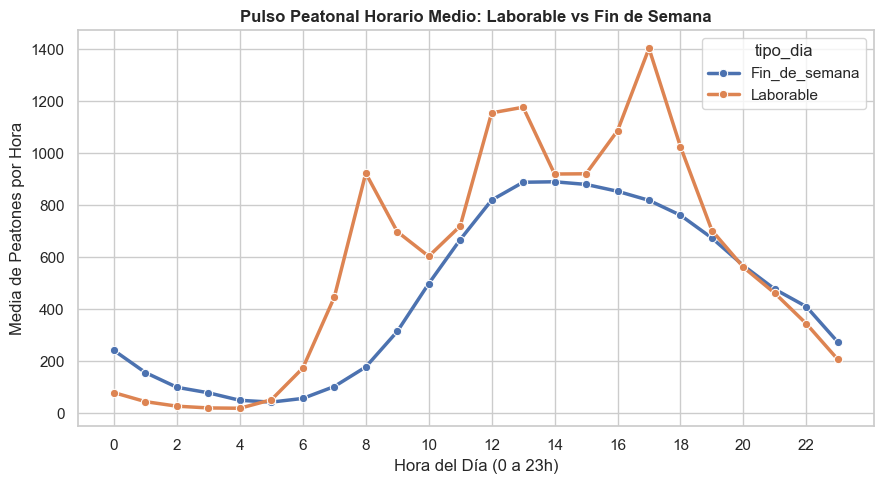

In [4]:
dias_finde = ['Saturday', 'Sunday']
peatones_val['tipo_dia'] = np.where(peatones_val['Day'].isin(dias_finde), 'Fin_de_semana', 'Laborable')
dummies_dia = pd.get_dummies(peatones_val['tipo_dia'], dtype=int)
peatones_val = pd.concat([peatones_val, dummies_dia], axis=1)

curva_horaria = peatones_val.groupby(['Time', 'tipo_dia'])['Hourly_Counts'].mean().reset_index()
plt.figure(figsize=(9, 5))
sns.lineplot(data=curva_horaria, x='Time', y='Hourly_Counts', hue='tipo_dia', marker='o', linewidth=2.5)
plt.title('Pulso Peatonal Horario Medio: Laborable vs Fin de Semana', fontweight='bold')
plt.xlabel('Hora del Día (0 a 23h)')
plt.ylabel('Media de Peatones por Hora')
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

### 1.4. Construcción de la tabla maestra (Peatones + Negocios a 200m) y Escalado (`StandardScaler`)
Construyo una tabla resumen donde cada fila es uno de los 41 sensores y las **11 variables numéricas** recogen:
* **4 franjas horarias:** `flujo_manana` (6 a 10h), `flujo_mediodia` (11 a 15h), `flujo_tarde` (16 a 20h) y `flujo_noche` (21 a 5h).
* **3 indicadores de día:** flujo medio en `Laborable`, en `Fin_de_semana` y la proporción `ratio_finde = Fin_de_semana / (Laborable + 1)`.
* **4 conteos de locales en un radio de 200 metros:** usando la distancia euclídea en metros desde las coordenadas de cada sensor, cuento cuántos `locales_vacios`, `cafes_restaurantes`, locales de `comida_llevar` (*Takeaway*) y `oficinas_servicios` (servicios legales, informáticos, financieros y consultoría) rodean al sensor.

Como los flujos peatonales llegan a casi 3.000 personas/hora y variables como `ratio_finde` rondan el valor 1, aplico `StandardScaler` para que todas las columnas tengan media 0 y desviación típica 1 antes de calcular distancias.

In [5]:
def obtener_franja(h):
    if 6 <= h <= 10:
        return 'manana'
    elif 11 <= h <= 15:
        return 'mediodia'
    elif 16 <= h <= 20:
        return 'tarde'
    else:
        return 'noche'

peatones_val['franja'] = peatones_val['Time'].apply(obtener_franja)
piv_franja = peatones_val.groupby(['Sensor_ID', 'franja'])['Hourly_Counts'].mean().unstack()
piv_franja.columns = [f'flujo_{c}' for c in piv_franja.columns]

piv_dia = peatones_val.groupby(['Sensor_ID', 'tipo_dia'])['Hourly_Counts'].mean().unstack()
piv_dia['ratio_finde'] = piv_dia['Fin_de_semana'] / (piv_dia['Laborable'] + 1)

RADIO_M = 200.0
registros_entorno = []
for _, s in sensores_validos.iterrows():
    sid = s['location_id']
    dy = (establecimientos['latitude'] - s['latitude']) * 111111.0
    dx = (establecimientos['longitude'] - s['longitude']) * 88000.0
    dist_m = np.sqrt(dx**2 + dy**2)
    cercanos = establecimientos[dist_m <= RADIO_M]
    conteos = cercanos['industry_anzsic4_description'].value_counts()
    registros_entorno.append({
        'Sensor_ID': sid,
        'nombre_sensor': s['sensor_description'],
        'latitud': s['latitude'],
        'longitud': s['longitude'],
        'locales_vacios': conteos.get('Vacant Space', 0),
        'cafes_restaurantes': conteos.get('Cafes and Restaurants', 0),
        'comida_llevar': conteos.get('Takeaway Food Services', 0),
        'oficinas_servicios': (
            conteos.get('Legal Services', 0) +
            conteos.get('Computer System Design and Related Services', 0) +
            conteos.get('Other Auxiliary Finance and Investment Services', 0) +
            conteos.get('Management Advice and Other Consulting Services', 0)
        ),
        'total_locales_200m': len(cercanos)
    })

df_entorno = pd.DataFrame(registros_entorno).set_index('Sensor_ID')
df_maestro = df_entorno.join(piv_franja).join(piv_dia[['Laborable', 'Fin_de_semana', 'ratio_finde']])

cols_numericas = [
    'locales_vacios', 'cafes_restaurantes', 'comida_llevar', 'oficinas_servicios',
    'flujo_manana', 'flujo_mediodia', 'flujo_tarde', 'flujo_noche',
    'Laborable', 'Fin_de_semana', 'ratio_finde'
]
scaler = StandardScaler()
df_escalado = pd.DataFrame(
    scaler.fit_transform(df_maestro[cols_numericas]),
    index=df_maestro.index,
    columns=cols_numericas
)
X = df_escalado.values
print(f'Tabla maestra: {df_maestro.shape[0]} sensores x {len(cols_numericas)} variables')

Tabla maestra: 41 sensores x 11 variables


---
## Fase 2: Tendencia de Clustering y Reducción de la Dimensión
Antes de aplicar los algoritmos de agrupamiento, compruebo dos puntos vistos en los **Temas 2 y 4**:

### 2.1. Evaluación de la tendencia de agrupamiento (Estadístico de Hopkins)
Como K-Means divide cualquier nube de puntos aunque sea aleatoria, verifico primero si nuestros datos tienen estructura real de grupos mediante el **estadístico de Hopkins** (promediando 50 simulaciones). El resultado es **$H = 0,7490$** en la definición clásica (cercano a 1 indica agrupamiento claro frente a 0,50 aleatorio) y **$1 - H = 0,2510$** en el criterio de Python (cercano a 0), confirmando que los sensores sí tienden a formar clústeres naturales.

In [6]:
# 1. Estadístico de Hopkins (Tema 4)
def calcular_hopkins(X, m=None, seed=42):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    if m is None:
        m = int(0.5 * n)
    idx = rng.choice(n, size=m, replace=False)
    q = X[idx]
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    d_q = nn.kneighbors(q, n_neighbors=2)[0][:, 1]
    p = rng.uniform(X.min(axis=0), X.max(axis=0), size=(m, d))
    d_p = nn.kneighbors(p, n_neighbors=1)[0][:, 0]
    H = np.sum(d_p) / (np.sum(d_p) + np.sum(d_q))
    return H, 1.0 - H

H_vals, inv_H_vals = zip(*[calcular_hopkins(X, seed=i) for i in range(50)])
print(f'Estadístico de Hopkins clásico (H):  {np.mean(H_vals):.4f} (cercano a 1 indica que sí hay clústeres)')
print(f'Estadístico de Hopkins Python (1-H): {np.mean(inv_H_vals):.4f} (cercano a 0 indica que sí hay clústeres)')

Estadístico de Hopkins clásico (H):  0.7490 (cercano a 1 indica que sí hay clústeres)
Estadístico de Hopkins Python (1-H): 0.2510 (cercano a 0 indica que sí hay clústeres)


### 2.2. Reducción de la dimensión con PCA
Aplico **PCA (Análisis de Componentes Principales)** sobre las 11 variables estandarizadas para proyectar los sensores en un plano 2D. La primera componente (**PC1**) recoge el **52,2%** de la varianza (volumen general peatonal y comercial) y la segunda (**PC2**) explica otro **18,9%** (diferencia entre zonas matutinas de oficinas y zonas de ocio/fin de semana). En total, con solo 2 dimensiones conservamos el **71,0%** de la información original.

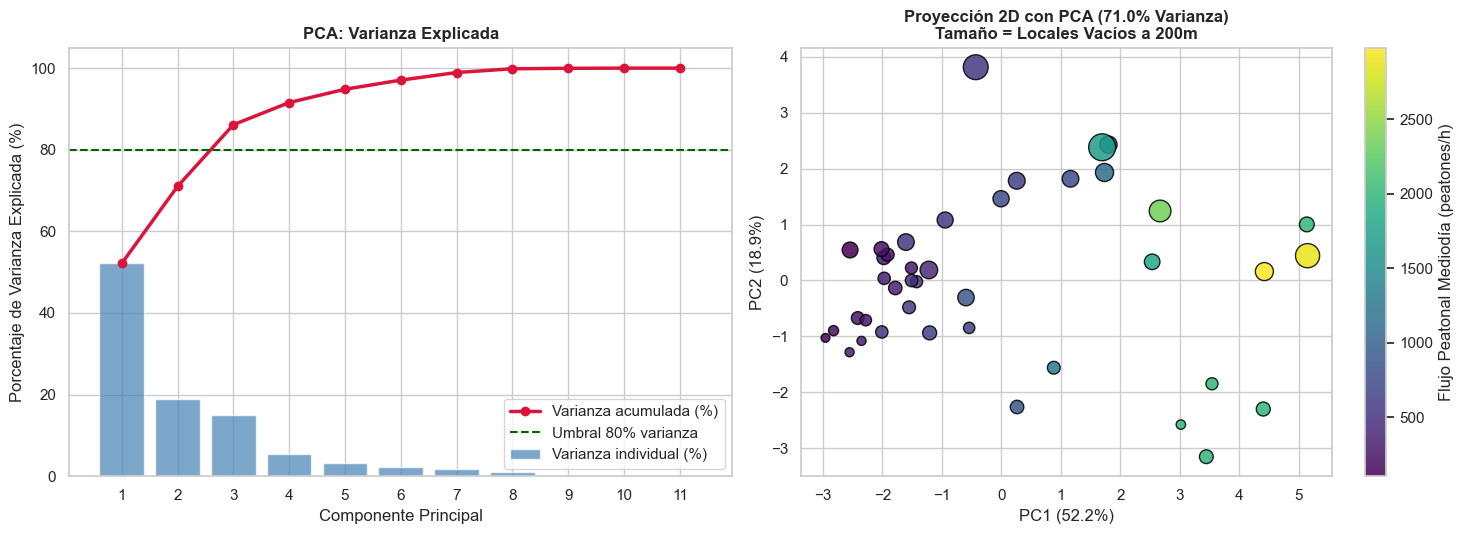

In [7]:
# 2. Reducción de dimensión con PCA
pca_full = PCA().fit(X)
var_exp = pca_full.explained_variance_ratio_ * 100
var_acum = np.cumsum(var_exp)

pca_2d = PCA(n_components=2, random_state=42)
coords_pca = pca_2d.fit_transform(X)

df_proy = df_maestro.copy()
df_proy['PCA_1'], df_proy['PCA_2'] = coords_pca[:, 0], coords_pca[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

componentes = np.arange(1, len(var_exp) + 1)
axes[0].bar(componentes, var_exp, alpha=0.7, color='steelblue', label='Varianza individual (%)')
axes[0].plot(componentes, var_acum, marker='o', color='crimson', linewidth=2.5, label='Varianza acumulada (%)')
axes[0].axhline(80, color='darkgreen', linestyle='--', label='Umbral 80% varianza')
axes[0].set_title('PCA: Varianza Explicada', fontweight='bold')
axes[0].set_xlabel('Componente Principal')
axes[0].set_ylabel('Porcentaje de Varianza Explicada (%)')
axes[0].set_xticks(componentes)
axes[0].legend()

sc = axes[1].scatter(df_proy['PCA_1'], df_proy['PCA_2'], c=df_proy['flujo_mediodia'], cmap='viridis',
                     s=df_proy['locales_vacios'] * 1.5 + 40, alpha=0.85, edgecolors='black')
plt.colorbar(sc, ax=axes[1], label='Flujo Peatonal Mediodía (peatones/h)')
axes[1].set_title(f'Proyección 2D con PCA ({var_acum[1]:.1f}% Varianza)\nTamaño = Locales Vacíos a 200m', fontweight='bold')
axes[1].set_xlabel(f'PC1 ({var_exp[0]:.1f}%)')
axes[1].set_ylabel(f'PC2 ({var_exp[1]:.1f}%)')
plt.tight_layout()
plt.show()

---
## Fase 3: Modelado No Supervisado (K-Means++, Clustering Jerárquico y DBSCAN)
En esta fase comparo las tres familias de algoritmos de clustering estudiadas en el **Tema 3**:

### 3.1. Algoritmo K-Means++ y Método del Codo (WCSS)
Calculo la inercia intra-clúster (WCSS) desde $K=1$ hasta $K=10$. En la curva del **Método del Codo** se observa que a partir de **$K=3$** la pendiente se suaviza, dividiendo las calles de Melbourne en tres perfiles comerciales muy claros:
* **Clúster 0 — Ocio, Finde y Gastronomía (9 sensores):** alta actividad en fin de semana (`ratio_finde = 1,0`), récord de cafeterías/restaurantes (media de 113,0) y gran disponibilidad de locales vacíos (107,9).
* **Clúster 1 — Tránsito Laborable / Oficinas (25 sensores):** agrupa la mayoría de calles de paso laboral con tráfico moderado entre semana (470,2 peat./h al mediodía) que baja el fin de semana (`ratio_finde = 0,7`).
* **Clúster 2 — Arterias Prime Alto Flujo (7 sensores):** los grandes ejes peatonales de la ciudad, que superan los 2.260 peatones/hora tanto al mediodía como por la tarde.

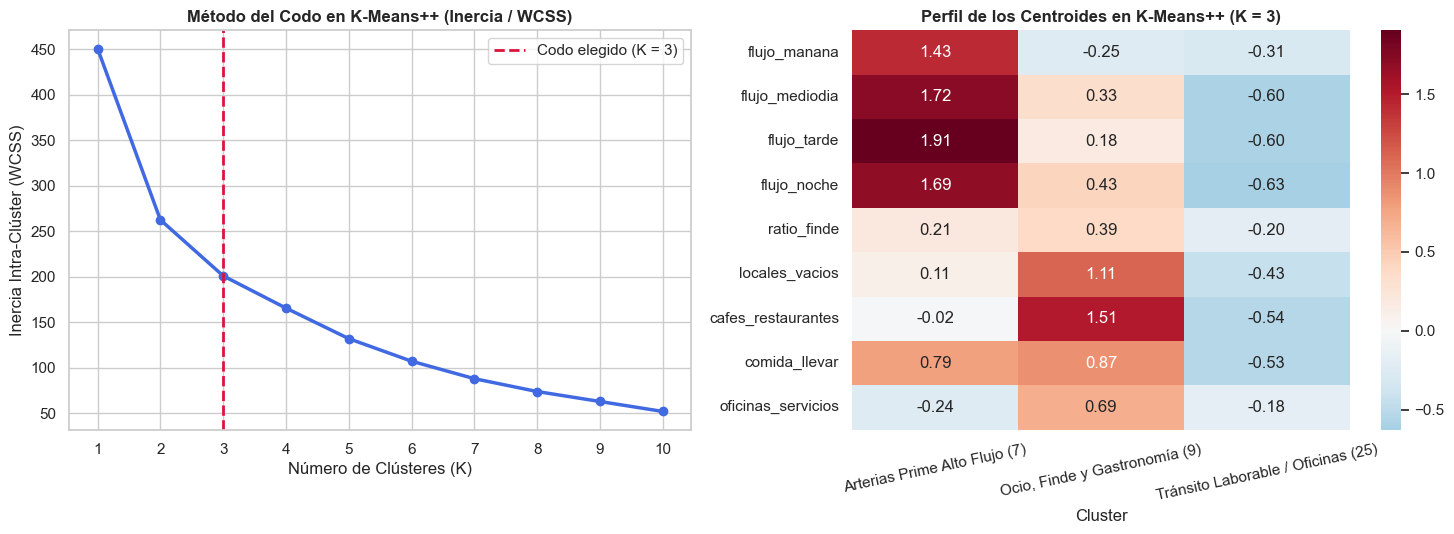

,flujo_manana,flujo_mediodia,flujo_tarde,flujo_noche,ratio_finde,locales_vacios,cafes_restaurantes,comida_llevar,oficinas_servicios
KMeans_nombre,,,,,,,,,
Arterias Prime Alto Flujo (7),1089.3,2262.0,2337.3,404.4,0.9,59.7,50.3,42.0,25.6
"Ocio, Finde y Gastronomía (9)",363.3,1192.6,1026.5,219.1,1.0,107.9,113.0,44.0,90.6
Tránsito Laborable / Oficinas (25),336.4,470.2,437.6,65.3,0.7,33.4,29.2,9.8,29.8


In [8]:
# 1. K-Means++ y Método del Codo
K_range = list(range(1, 11))
inercias = [KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=42).fit(X).inertia_ for k in K_range]

kmeans_final = KMeans(n_clusters=3, init='k-means++', n_init=20, random_state=42)
df_proy['KMeans_cluster'] = kmeans_final.fit_predict(X)

nombres_kmeans = {
    0: 'Ocio, Finde y Gastronomía (9)',
    1: 'Tránsito Laborable / Oficinas (25)',
    2: 'Arterias Prime Alto Flujo (7)',
}
df_proy['KMeans_nombre'] = df_proy['KMeans_cluster'].map(nombres_kmeans)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].plot(K_range, inercias, marker='o', linewidth=2.5, color='royalblue')
axes[0].axvline(3, color='crimson', linestyle='--', linewidth=2, label='Codo elegido (K = 3)')
axes[0].set_title('Método del Codo en K-Means++ (Inercia / WCSS)', fontweight='bold')
axes[0].set_xlabel('Número de Clústeres (K)')
axes[0].set_ylabel('Inercia Intra-Clúster (WCSS)')
axes[0].set_xticks(K_range)
axes[0].legend()

cols_perfil = ['flujo_manana', 'flujo_mediodia', 'flujo_tarde', 'flujo_noche',
               'ratio_finde', 'locales_vacios', 'cafes_restaurantes', 'comida_llevar', 'oficinas_servicios']
centroides_df = pd.DataFrame(df_escalado[cols_perfil]).assign(Cluster=df_proy['KMeans_nombre']).groupby('Cluster').mean()

sns.heatmap(centroides_df.T, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set_title('Perfil de los Centroides en K-Means++ (K = 3)', fontweight='bold')
axes[1].tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()

display(df_proy.groupby('KMeans_nombre')[cols_perfil].mean().round(1))

### 3.2. Clustering Jerárquico Aglomerativo (enlace Ward, K = 3)
Aplico el agrupamiento jerárquico aglomerativo con enlace `ward` y $K=3$ para contrastar su partición con la de K-Means++. El reparto resultante (grupos de 27, 10 y 4 sensores) guarda mucha coherencia con los tres arquetipos anteriores.

In [9]:
# 2. Clustering Jerárquico Aglomerativo (enlace Ward, K = 3)
df_proy['Jerarquico_cluster'] = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X)
print('Sensores por clúster (Ward):')
print(df_proy['Jerarquico_cluster'].value_counts().sort_index())

Sensores por clúster (Ward):
Jerarquico_cluster
0    27
1    10
2     4
Name: count, dtype: int64


### 3.3. Algoritmo DBSCAN: Clústeres Densos y Detección de Anomalías (`-1`)
Pruebo distintos valores del radio `eps` (entre 1,8 y 2,8) con `min_samples = 3`. En **`eps = 2.4`** la partición se estabiliza en 2 clústeres densos y **4 puntos marcados como ruido (`-1`)**. Al revisar la tabla de esos 4 sensores atípicos (**ID 4 Town Hall West**, **ID 53 Collins St North**, **ID 3 Melbourne Central** e **ID 36 Queen St West**), comprobamos que no son errores de medición, sino las esquinas con cifras más extremas de toda la ciudad (por ejemplo, el mayor número de locales vacíos de los 41 sensores con 224 en Collins St North o 2.882 peatones/hora con 175 locales vacíos en Town Hall West).

> *Nota:* Los sensores 4 y 53 distan solo 99 m entre sí (véase el apartado 5.5), por lo que en la práctica son un mismo foco comercial observado desde dos sensores y sus cifras de locales vacíos no deben sumarse.

eps=1.8: 3 clústeres | 13 puntos de ruido
eps=2.0: 2 clústeres | 9 puntos de ruido
eps=2.2: 2 clústeres | 7 puntos de ruido
eps=2.4: 2 clústeres | 4 puntos de ruido
eps=2.6: 2 clústeres | 4 puntos de ruido
eps=2.8: 2 clústeres | 2 puntos de ruido


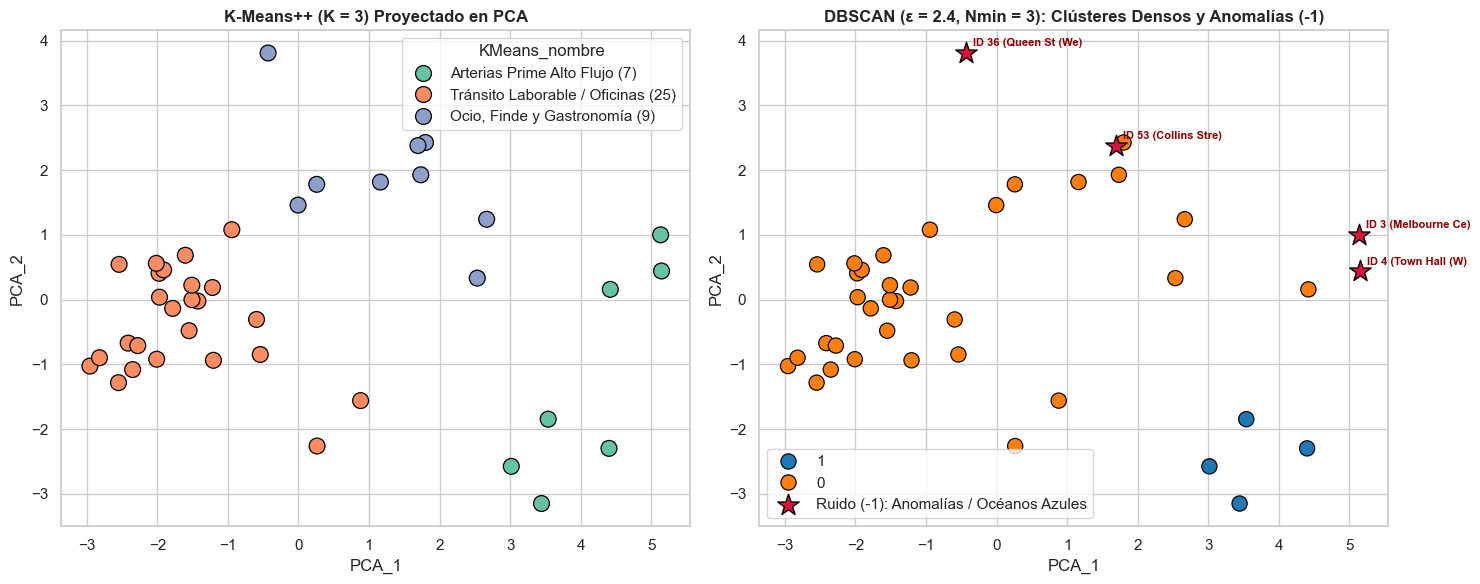

,nombre_sensor,KMeans_nombre,flujo_mediodia,flujo_tarde,ratio_finde,locales_vacios,cafes_restaurantes,oficinas_servicios
Sensor_ID,,,,,,,,
3,Melbourne Central,Arterias Prime Alto Flujo (7),2002.3,2353.7,1.0,49,100,27
53,Collins Street (North),"Ocio, Finde y Gastronomía (9)",1683.1,944.1,0.7,224,86,119
4,Town Hall (West),Arterias Prime Alto Flujo (7),2882.4,2465.3,0.9,175,66,68
36,Queen St (West),"Ocio, Finde y Gastronomía (9)",573.5,407.1,0.5,187,66,412


In [10]:
# 3. DBSCAN: clústeres densos y detección de anomalías / Océanos Azules (-1)

# Sensibilidad al parámetro eps (comprobación rápida; EPS se fija en la primera celda)
for e in [1.8, 2.0, 2.2, 2.4, 2.6, 2.8]:
    lab = DBSCAN(eps=e, min_samples=3).fit_predict(X)
    print(f'eps={e}: {len(set(lab.tolist()) - {-1})} clústeres | {int((lab == -1).sum())} puntos de ruido')

dbscan_model = DBSCAN(eps=EPS, min_samples=3)
df_proy['DBSCAN_cluster'] = dbscan_model.fit_predict(X)
df_proy['DBSCAN_etiqueta'] = df_proy['DBSCAN_cluster'].astype(str)
es_ruido = df_proy['DBSCAN_cluster'] == -1

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=df_proy, x='PCA_1', y='PCA_2', hue='KMeans_nombre', palette='Set2',
                s=130, edgecolor='black', ax=axes[0])
axes[0].set_title('K-Means++ (K = 3) Proyectado en PCA', fontweight='bold')

sns.scatterplot(data=df_proy[~es_ruido], x='PCA_1', y='PCA_2', hue='DBSCAN_etiqueta', palette='tab10',
                s=120, edgecolor='black', ax=axes[1])
axes[1].scatter(df_proy.loc[es_ruido, 'PCA_1'], df_proy.loc[es_ruido, 'PCA_2'], color='crimson', marker='*',
                s=260, edgecolor='black', label='Ruido (-1): Anomalías / Océanos Azules')
for sid, r in df_proy[es_ruido].iterrows():
    axes[1].annotate(f"ID {sid} ({r['nombre_sensor'][:12]})", (r['PCA_1'] + 0.1, r['PCA_2'] + 0.1),
                     fontsize=8, fontweight='bold', color='darkred')
axes[1].set_title(f'DBSCAN (ε = {EPS}, Nmin = 3): Clústeres Densos y Anomalías (-1)', fontweight='bold')
axes[1].legend(loc='best')
plt.tight_layout()
plt.show()

display(df_proy[es_ruido][['nombre_sensor', 'KMeans_nombre', 'flujo_mediodia', 'flujo_tarde',
                           'ratio_finde', 'locales_vacios', 'cafes_restaurantes', 'oficinas_servicios']].round(1))

---
## Fase 4: Selección y Evaluación de Modelos (Tema 4)
Siguiendo el **Tema 4**, evalúo los tres modelos mediante criterios internos y criterios externos ante ruido:

### 4.1. Criterios Internos (Coeficiente de Silueta y Davies-Bouldin)
Mido la compacidad y separación de los grupos sin usar referencias externas. En **DBSCAN** (evaluado sobre los puntos agrupados sin contar el ruido `-1`) se obtiene la mejor Silueta (**0,423**) y el menor Davies-Bouldin (**0,758**), seguido muy de cerca por el Jerárquico Ward (Silueta **0,396**) y K-Means++ (Silueta **0,386**).

In [11]:
# 1. Criterios Internos (en DBSCAN se excluyen los puntos de ruido)
def metricas_internas(X_, labs):
    if len(set(labs.tolist())) < 2:
        return np.nan, np.nan
    return silhouette_score(X_, labs), davies_bouldin_score(X_, labs)

modelos_eval = {
    'K-Means++ (K=3)': df_proy['KMeans_cluster'].values,
    'Jerárquico Ward (K=3)': df_proy['Jerarquico_cluster'].values,
    'DBSCAN (sin ruido)': df_proy['DBSCAN_cluster'].values
}

tabla_internos = []
for nombre, labs in modelos_eval.items():
    mask = (labs != -1) if 'DBSCAN' in nombre else np.ones(len(labs), dtype=bool)
    sil, db = metricas_internas(X[mask], labs[mask])
    tabla_internos.append({
        'Algoritmo': nombre,
        'Silhouette (↑ mejor)': round(sil, 3),
        'Davies-Bouldin (↓ mejor)': round(db, 3)
    })
df_internos = pd.DataFrame(tabla_internos)
print('=== CRITERIOS INTERNOS ===')
display(df_internos)

=== CRITERIOS INTERNOS ===


,Algoritmo,Silhouette (↑ mejor),Davies-Bouldin (↓ mejor)
0,K-Means++ (K=3),0.386,1.150
1,Jerárquico Ward (K=3),0.396,1.001
2,DBSCAN (sin ruido),0.423,0.758


### 4.2. Criterios Externos: Prueba de estabilidad frente al ruido (ARI y V-Medida)
Como no existen etiquetas reales previas, aplico el procedimiento visto en el Tema 4 para evaluar la sensibilidad al ruido: tomo las etiquetas originales de cada algoritmo y las comparo en 30 repeticiones frente a las etiquetas que salen tras sumar ruido gaussiano ($\sigma = 0,25$) a los datos. Aquí **K-Means++ demuestra ser el modelo más estable** (**ARI = 0,897** y **V-Medida = 0,864**), mientras que DBSCAN es más sensible en los bordes del radio `eps` (ARI = 0,641). Por eso en la Fase 5 aprovecho ambos de forma complementaria.

=== CRITERIOS EXTERNOS (ESTABILIDAD FRENTE AL RUIDO) ===


,Algoritmo,Rand Ajustado (ARI),V-Medida
0,K-Means++ (K=3),0.897,0.864
1,Jerárquico Ward (K=3),0.760,0.738
2,"DBSCAN (eps=2.4, Nmin=3)",0.641,0.621


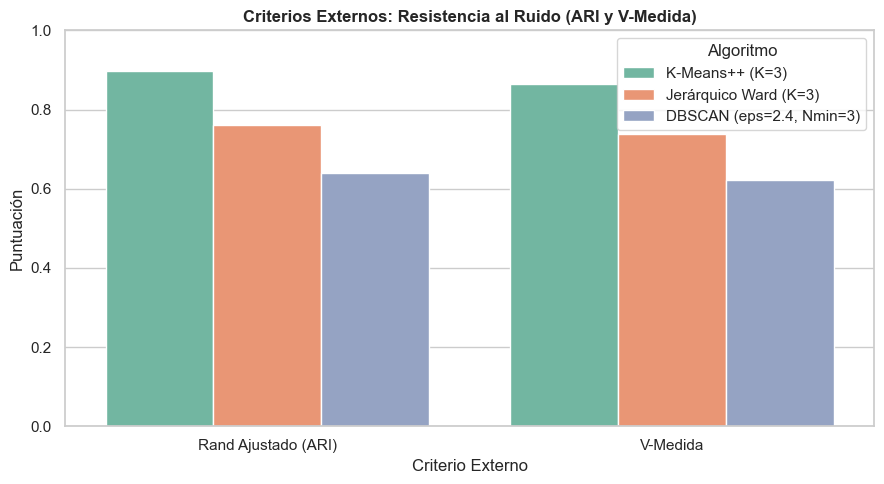

In [12]:
# 2. Criterios Externos ante Ruido (Rand Ajustado ARI y V-Medida)
rng = np.random.default_rng(42)
algoritmos_ruido = {
    'K-Means++ (K=3)': lambda d: KMeans(n_clusters=3, init='k-means++', n_init=20, random_state=42).fit_predict(d),
    'Jerárquico Ward (K=3)': lambda d: AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(d),
    f'DBSCAN (eps={EPS}, Nmin=3)': lambda d: DBSCAN(eps=EPS, min_samples=3).fit_predict(d)
}

tabla_externos = []
for nombre, func in algoritmos_ruido.items():
    labs_orig = func(X)
    metricas_rep = []
    for _ in range(30):
        labs_ruido = func(X + rng.normal(0, 0.25, size=X.shape))
        metricas_rep.append([
            adjusted_rand_score(labs_orig, labs_ruido),
            v_measure_score(labs_orig, labs_ruido)
        ])
    medias = np.mean(metricas_rep, axis=0)
    tabla_externos.append({
        'Algoritmo': nombre,
        'Rand Ajustado (ARI)': round(medias[0], 3),
        'V-Medida': round(medias[1], 3)
    })
df_externos = pd.DataFrame(tabla_externos)
print('=== CRITERIOS EXTERNOS (ESTABILIDAD FRENTE AL RUIDO) ===')
display(df_externos)

df_ext_melt = df_externos.melt(id_vars='Algoritmo', var_name='Criterio Externo', value_name='Puntuación')
plt.figure(figsize=(9, 5))
sns.barplot(data=df_ext_melt, x='Criterio Externo', y='Puntuación', hue='Algoritmo', palette='Set2')
plt.title('Criterios Externos: Resistencia al Ruido (ARI y V-Medida)', fontweight='bold')
plt.ylim(0, 1.0)
plt.tight_layout()
plt.show()

---
## Fase 5: Decisión de Negocio, Sensibilidad y Validación Espacial

### 5.1. Cálculo del Score de Oportunidad Comercial y Direcciones Exactas
Para recomendar en qué calles invertir para abrir un café saludable, exijo primero que el sensor tenga al menos 15 locales vacíos alrededor (`locales_vacios >= 15`) para asegurar que hay varios locales vacíos entre los que elegir. Después calculo la demanda peatonal por cada competidor actual (`demanda_por_cafe` y `demanda_por_takeaway`) y construyo el **Score de Oportunidad Comercial (0 a 100)** fijando los pesos *a priori* por criterio de negocio:
* **0,5 para `demanda_por_cafe`:** porque el negocio objetivo es un café saludable y esta ratio mide directamente cuántos clientes potenciales pasan por cada competidor directo (las cafeterías).
* **0,3 para `demanda_por_takeaway`:** porque es competencia relacionada o sustitutiva (comida rápida de paso), pero menos directa.
* **0,2 para `locales_vacios`:** porque tener locales vacíos cerca es una condición necesaria para entrar, no una medida de demanda de clientes; además, el filtro de al menos 15 locales vacíos ya garantiza que hay locales suficientes entre los que elegir.

Finalmente, cruzo las coordenadas de los **3 sensores ganadores (IDs 24, 4 y 53)** con `establecimientos_2019.csv` en un radio corto de 120 metros y extraigo las direcciones postales exactas de los locales vacíos más cercanos.

> *Nota:* Los 175 y 224 locales vacíos de los sensores 4 y 53 no son sumables, ya que ambos sensores comparten parte de ellos (véase el apartado 5.5).

In [13]:
df_proy['demanda_por_cafe'] = (df_proy['flujo_mediodia'] + df_proy['flujo_tarde']) / (df_proy['cafes_restaurantes'] + 5)
df_proy['demanda_por_takeaway'] = (df_proy['flujo_manana'] + df_proy['flujo_mediodia'] + df_proy['flujo_tarde']) / (df_proy['comida_llevar'] + 5)
df_proy['score_oportunidad'] = (
    0.5 * (df_proy['demanda_por_cafe'] / df_proy['demanda_por_cafe'].max()) +
    0.3 * (df_proy['demanda_por_takeaway'] / df_proy['demanda_por_takeaway'].max()) +
    0.2 * (df_proy['locales_vacios'] / df_proy['locales_vacios'].max())
) * 100

top_sensores = df_proy[df_proy['locales_vacios'] >= 15].sort_values('score_oportunidad', ascending=False)
print('=== TOP ZONAS RECOMENDADAS PARA INVERTIR ===')
display(top_sensores[['nombre_sensor', 'KMeans_nombre', 'DBSCAN_cluster', 'flujo_mediodia', 'cafes_restaurantes',
                      'comida_llevar', 'locales_vacios', 'demanda_por_cafe', 'score_oportunidad']].head(6).round(1))

vacios_df = establecimientos[establecimientos['industry_anzsic4_description'] == 'Vacant Space'].copy()
sensores_ganadores = [24, 4, 53]
locales_recomendados = []

for sid in sensores_ganadores:
    s_row = df_proy.loc[sid]
    dy = (vacios_df['latitude'] - s_row['latitud']) * 111111.0
    dx = (vacios_df['longitude'] - s_row['longitud']) * 88000.0
    vacios_df['distancia_m'] = np.sqrt(dx**2 + dy**2)
    cercanos = vacios_df[vacios_df['distancia_m'] <= 120.0].copy()
    resumen_dir = (
        cercanos.groupby(['business_address', 'clue_small_area'])
        .agg(unidades_vacias=('property_id', 'count'), distancia_min_m=('distancia_m', 'min'))
        .reset_index()
        .sort_values(['distancia_min_m', 'unidades_vacias'], ascending=[True, False])
    )
    for _, r in resumen_dir.head(3).iterrows():
        locales_recomendados.append({
            'Sensor_ID': sid,
            'Zona_Sensor': s_row['nombre_sensor'],
            'Arquetipo_KMeans': s_row['KMeans_nombre'],
            'Direccion_Exacta_Local': r['business_address'],
            'Distancia_al_Sensor_m': round(r['distancia_min_m'], 1),
            'Flujo_Mediodia_Peatones_h': round(s_row['flujo_mediodia'], 0),
            'Score_Oportunidad': round(s_row['score_oportunidad'], 1)
        })

df_recom_final = pd.DataFrame(locales_recomendados)
print('\n=== DIRECCIONES EXACTAS DE LOCALES VACÍOS RECOMENDADOS ===')
display(df_recom_final)

=== TOP ZONAS RECOMENDADAS PARA INVERTIR ===


,nombre_sensor,KMeans_nombre,DBSCAN_cluster,flujo_mediodia,cafes_restaurantes,comida_llevar,locales_vacios,demanda_por_cafe,score_oportunidad
Sensor_ID,,,,,,,,,
24,Spencer St-Collins St (North),Arterias Prime Alto Flujo (7),1,1989.2,29,8,39,126.1,35.2
4,Town Hall (West),Arterias Prime Alto Flujo (7),-1,2882.4,66,37,175,75.3,28.9
53,Collins Street (North),"Ocio, Finde y Gastronomía (9)",-1,1683.1,86,43,224,28.9,25.5
6,Flinders Underpass - Myki Barriers,Arterias Prime Alto Flujo (7),1,1981.2,30,43,41,128.5,21.2
35,Southbank Promenade,Arterias Prime Alto Flujo (7),1,1984.4,28,29,24,125.1,20.5
36,Queen St (West),"Ocio, Finde y Gastronomía (9)",-1,573.5,66,29,187,13.8,19.6



=== DIRECCIONES EXACTAS DE LOCALES VACÍOS RECOMENDADOS ===


,Sensor_ID,Zona_Sensor,Arquetipo_KMeans,Direccion_Exacta_Local,Distancia_al_Sensor_m,Flujo_Mediodia_Peatones_h,Score_Oportunidad
0,24,Spencer St-Collins St (North),Arterias Prime Alto Flujo (7),"Shop 1, 608-610 Collins Street MELBOURNE 3000",30.5,1989.0,35.2
1,24,Spencer St-Collins St (North),Arterias Prime Alto Flujo (7),"Shop 4, 608-610 Collins Street MELBOURNE 3000",30.5,1989.0,35.2
2,24,Spencer St-Collins St (North),Arterias Prime Alto Flujo (7),"Shop 5, 608-610 Collins Street MELBOURNE 3000",30.5,1989.0,35.2
3,4,Town Hall (West),Arterias Prime Alto Flujo (7),"Level 4, 123 Swanston Street MELBOURNE 3000",18.7,2882.0,28.9
4,4,Town Hall (West),Arterias Prime Alto Flujo (7),125-133 Swanston Street MELBOURNE 3000,29.9,2882.0,28.9
5,4,Town Hall (West),Arterias Prime Alto Flujo (7),133 Swanston Street MELBOURNE 3000,29.9,2882.0,28.9
6,53,Collins Street (North),"Ocio, Finde y Gastronomía (9)","Basement , 252 Collins Street MELBOURNE 3000",19.4,1683.0,25.5
7,53,Collins Street (North),"Ocio, Finde y Gastronomía (9)","Ground , 252 Collins Street MELBOURNE 3000",19.4,1683.0,25.5
8,53,Collins Street (North),"Ocio, Finde y Gastronomía (9)","Level 1, 252 Collins Street MELBOURNE 3000",19.4,1683.0,25.5


### 5.2. Visualización de la Matriz de Decisión Comercial
Represento en un gráfico de burbujas la demanda peatonal (mediodía + tarde) frente al número de competidores directos en 200 metros, donde el tamaño de cada círculo indica el número de locales vacíos disponibles y el color refleja el Score de Oportunidad.

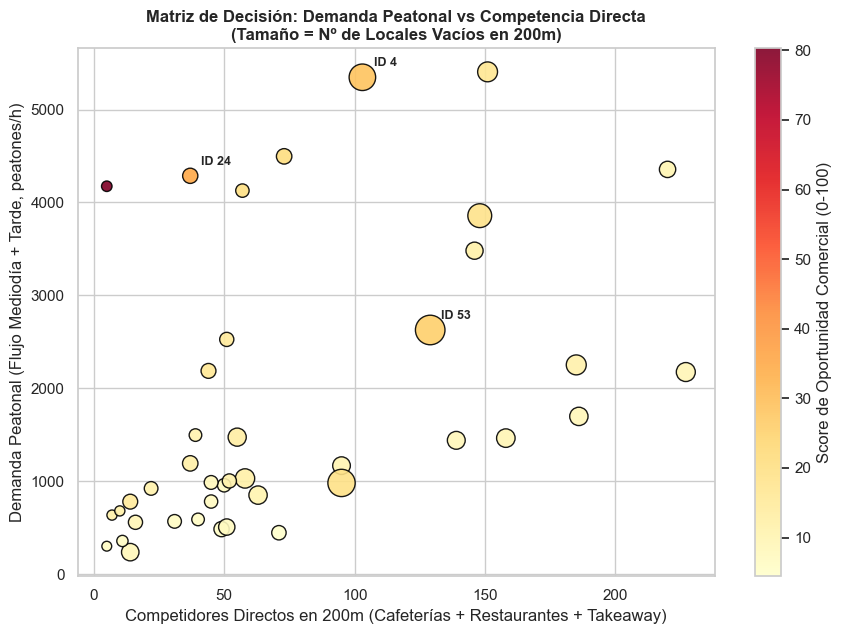

In [14]:
# Matriz de decisión: demanda peatonal vs competencia directa
fig, ax = plt.subplots(figsize=(9, 6.5))
x_comp = df_proy['cafes_restaurantes'] + df_proy['comida_llevar']
y_dem = df_proy['flujo_mediodia'] + df_proy['flujo_tarde']
sc = ax.scatter(x_comp, y_dem, c=df_proy['score_oportunidad'], cmap='YlOrRd',
                s=df_proy['locales_vacios'] * 1.8 + 50, edgecolor='black', alpha=0.9)
plt.colorbar(sc, ax=ax, label='Score de Oportunidad Comercial (0-100)')
for sid in sensores_ganadores:
    ax.annotate(f'ID {sid}', (x_comp.loc[sid], y_dem.loc[sid]), textcoords='offset points',
                xytext=(8, 8), fontsize=9, fontweight='bold')
ax.set_title('Matriz de Decisión: Demanda Peatonal vs Competencia Directa\n(Tamaño = Nº de Locales Vacíos en 200m)', fontweight='bold')
ax.set_xlabel('Competidores Directos en 200m (Cafeterías + Restaurantes + Takeaway)')
ax.set_ylabel('Demanda Peatonal (Flujo Mediodía + Tarde, peatones/h)')
plt.tight_layout()
plt.show()

### 5.3. Mejor Sensor por Arquetipo de K-Means++
Para conectar el clustering con la recomendación, calculo también el sensor con mayor Score de Oportunidad dentro de cada arquetipo de K-Means++ (siempre entre los que cumplen el filtro de al menos 15 locales vacíos). *Town Hall West* (ID 4, Score 28,9) es el segundo mejor sensor de las *Arterias Prime*, por lo que no aparece como el primero de su grupo pero sí forma parte del Top 3 global. El mejor sensor de las calles de tránsito laborable (**ID 9: Southern Cross Station**) puntúa menos de la mitad que el de las arterias principales (16,6 frente a 35,2), y además está a 323 m del sensor 24, por lo que es una zona contigua y no una recomendación independiente.

In [15]:
top_por_arquetipo = (top_sensores.groupby('KMeans_nombre')
                     .head(1)  # pon head(2) para los 2 mejores de cada grupo
                     .sort_values('score_oportunidad', ascending=False))
display(top_por_arquetipo[['nombre_sensor', 'KMeans_nombre', 'flujo_mediodia',
                           'cafes_restaurantes', 'locales_vacios', 'score_oportunidad']].round(1))

,nombre_sensor,KMeans_nombre,flujo_mediodia,cafes_restaurantes,locales_vacios,score_oportunidad
Sensor_ID,,,,,,
24,Spencer St-Collins St (North),Arterias Prime Alto Flujo (7),1989.2,29,39,35.2
53,Collins Street (North),"Ocio, Finde y Gastronomía (9)",1683.1,86,224,25.5
9,Southern Cross Station,Tránsito Laborable / Oficinas (25),869.2,21,36,16.6


### 5.4. Análisis de Sensibilidad y Validación de Robustez de los Pesos
Para comprobar que estas tres zonas no salieron ganadoras por haber puesto a mano los pesos `0,5 / 0,3 / 0,2`, ejecuto un análisis de sensibilidad con **5.000 combinaciones aleatorias de pesos** que suman 1 (usando una distribución de Dirichlet). El resultado confirma la solidez de la decisión: **Town Hall West (ID 4)** sale en el Top 3 en el **87,3%** de las 5.000 simulaciones, **Collins Street North (ID 53)** en el **70,6%** y **Spencer St-Collins St North (ID 24)** en el **60,2%**, muy por delante del cuarto sensor (*Queen St West* con un 39,7%). Es decir, elegí los pesos por criterio de negocio y luego comprobé que la conclusión se mantiene igual aunque cambies la ponderación. Hay que matizar que los sensores 4 y 53 comparten entorno (véase el apartado 5.5), por lo que sus porcentajes no son pruebas independientes.

In [16]:
# Análisis de Sensibilidad y Validación de Robustez de los Pesos (5.000 combinaciones que suman 1)
rng = np.random.default_rng(42)
comp = pd.DataFrame({
    'cafe': df_proy['demanda_por_cafe'] / df_proy['demanda_por_cafe'].max(),
    'take': df_proy['demanda_por_takeaway'] / df_proy['demanda_por_takeaway'].max(),
    'vacios': df_proy['locales_vacios'] / df_proy['locales_vacios'].max()
})
elegibles = df_proy['locales_vacios'] >= 15
pesos = rng.dirichlet([1, 1, 1], size=5000)

veces_top3 = pd.Series(0, index=df_proy.index)
for w in pesos:
    s = (comp @ w)[elegibles]
    veces_top3.loc[s.nlargest(3).index] += 1

robustez = (veces_top3 / len(pesos) * 100).sort_values(ascending=False)
display(pd.DataFrame({
    'sensor': df_proy.loc[robustez.index, 'nombre_sensor'],
    '% de veces en el top 3': robustez.round(1)
}).head(8))

,sensor,% de veces en el top 3
Sensor_ID,,
4,Town Hall (West),87.3
53,Collins Street (North),70.6
24,Spencer St-Collins St (North),60.2
36,Queen St (West),39.7
35,Southbank Promenade,18.3
6,Flinders Underpass - Myki Barriers,14.7
12,New Quay,8.7
40,Lonsdale St-Spring St (West),0.5


### 5.5. Validación Espacial del Top 3
Como verificación final, calculo la distancia entre los tres sensores ganadores y represento en un mapa con `folium` su radio de influencia de 200 m junto con los locales vacíos a menos de 120 m.

El análisis muestra que los sensores **4 (Town Hall West)** y **53 (Collins Street North)** están separados por solo **99 m**, por lo que sus radios se solapan en gran medida y comparten parte de su entorno comercial. Al calcular los establecimientos únicos que quedan dentro de la unión de ambos radios, vemos que en total hay **247 locales vacíos únicos** (y no los 399 de la suma simple de 175 + 224) y **97 cafés y restaurantes únicos** (frente a los 152 de la suma simple); es decir, alrededor del 38% de los locales vacíos y el 36% de los cafés de la suma simple quedan contados dos veces. Por su parte, el **sensor 24 (Spencer St-Collins St)** se encuentra a **1.033 m** del 53 y a **1.113 m** del 4, por lo que es una zona independiente.

En consecuencia, el Top 3 de sensores equivale en la práctica a **dos zonas comerciales distintas**: el entorno de *Spencer St-Collins St* y el eje *Collins St-Swanston St*.

In [17]:
from itertools import combinations

def dist_m(a, b):
    dy = (a['latitud'] - b['latitud']) * 111111.0
    dx = (a['longitud'] - b['longitud']) * 88000.0
    return np.sqrt(dx**2 + dy**2)

def unicos_en_zona(ids, categoria, radio=200.0):
    sub = establecimientos[establecimientos['industry_anzsic4_description'] == categoria]
    mask = np.zeros(len(sub), dtype=bool)
    for sid in ids:
        s = df_proy.loc[sid]
        dy = (sub['latitude'] - s['latitud']) * 111111.0
        dx = (sub['longitude'] - s['longitud']) * 88000.0
        mask |= (np.sqrt(dx**2 + dy**2) <= radio).values
    return int(mask.sum())

top3 = df_proy.loc[sensores_ganadores]
for i, j in combinations(top3.index, 2):
    print(f"Sensor {i} - Sensor {j}: {dist_m(top3.loc[i], top3.loc[j]):.0f} m")

print('\nZona Collins-Swanston (sensores 4 y 53), locales únicos en 200 m:')
print(f"  Vacíos: {unicos_en_zona([4, 53], 'Vacant Space')} (suma simple: {int(df_proy.loc[[4, 53], 'locales_vacios'].sum())})")
print(f"  Cafés/restaurantes: {unicos_en_zona([4, 53], 'Cafes and Restaurants')} (suma simple: {int(df_proy.loc[[4, 53], 'cafes_restaurantes'].sum())})")

Sensor 24 - Sensor 4: 1113 m
Sensor 24 - Sensor 53: 1033 m
Sensor 4 - Sensor 53: 99 m

Zona Collins-Swanston (sensores 4 y 53), locales únicos en 200 m:
  Vacíos: 247 (suma simple: 399)
  Cafés/restaurantes: 97 (suma simple: 152)


In [18]:
import folium

# Top 3 ordenado por score (usa sensores_ganadores y vacios_df de la celda 5.1)
orden = df_proy.loc[sensores_ganadores].sort_values('score_oportunidad', ascending=False)
colores = ['red', 'orange', 'blue']

mapa = folium.Map(
    location=[orden['latitud'].mean(), orden['longitud'].mean()],
    zoom_start=15, tiles='OpenStreetMap'
)

# Sensores: marcador + zona de influencia de 200 m (radio usado en el análisis)
for (sid, r), color, pos in zip(orden.iterrows(), colores, range(1, 4)):
    popup = folium.Popup(
        f"<b>#{pos} - Sensor {sid}: {r['nombre_sensor']}</b><br>"
        f"Arquetipo: {r['KMeans_nombre']}<br>"
        f"Score: {r['score_oportunidad']:.1f}<br>"
        f"Flujo mediodía: {r['flujo_mediodia']:.0f} peat./h<br>"
        f"Cafés/restaurantes (200 m): {int(r['cafes_restaurantes'])}<br>"
        f"Locales vacíos (200 m): {int(r['locales_vacios'])}",
        max_width=300
    )
    folium.Circle([r['latitud'], r['longitud']], radius=200, color=color,
                  fill=True, fill_opacity=0.15, weight=2).add_to(mapa)
    folium.Marker([r['latitud'], r['longitud']], popup=popup,
                  tooltip=f"#{pos} Sensor {sid}: {r['nombre_sensor']}",
                  icon=folium.Icon(color=color, icon='info-sign')).add_to(mapa)

# Locales vacíos a menos de 120 m de cada sensor (un punto por dirección)
for sid in orden.index:
    s = df_proy.loc[sid]
    dy = (vacios_df['latitude'] - s['latitud']) * 111111.0
    dx = (vacios_df['longitude'] - s['longitud']) * 88000.0
    cerca = vacios_df[np.sqrt(dx**2 + dy**2) <= 120.0]
    por_dir = (cerca.groupby('business_address')
               .agg(unidades=('property_id', 'count'), lat=('latitude', 'mean'), lon=('longitude', 'mean'))
               .reset_index())
    for _, v in por_dir.iterrows():
        folium.CircleMarker([v['lat'], v['lon']], radius=4, color='black', weight=1,
                            fill=True, fill_color='gray', fill_opacity=0.8,
                            tooltip=f"{v['business_address']} ({v['unidades']} unidades vacías)").add_to(mapa)

mapa.fit_bounds([[orden['latitud'].min() - 0.002, orden['longitud'].min() - 0.002],
                 [orden['latitud'].max() + 0.002, orden['longitud'].max() + 0.002]])

mapa.save('mapa_top3_melbourne.html')  # para adjuntarlo a la entrega
mapa

---
## Conclusiones del Trabajo
1. **El volumen anual de peatones por sí solo engaña:** Cruzar los conteos horarios con el censo comercial demostró que calles famosas como *Bourke Street Mall* tienen muchísimo tráfico pero están saturadas de competidores, mientras que otros nodos como el cruce de *Spencer St y Collins St* (Sensor 24) ofrecen casi 2.000 peatones por hora al mediodía con tres veces menos competencia directa.
2. **Los datos de Melbourne tienen una estructura clara en 3 perfiles:** El estadístico de Hopkins ($H = 0,7490$) confirmó que el agrupamiento no es azaroso, el PCA permitió resumir el $71,0\%$ de la varianza en solo 2 dimensiones, y tanto el método del codo en K-Means++ como el clustering jerárquico coincidieron en dividir la ciudad en 3 grupos bien diferenciados: calles de tránsito laborable (25), zonas de ocio y gastronomía (9) y arterias *prime* de alto flujo (7).
3. **K-Means++ y DBSCAN funcionan mejor juntos que por separado:** Al evaluar los modelos con las métricas del Tema 4 vimos que K-Means++ es el más estable frente al ruido aleatorio ($\text{ARI} = 0,897$), mientras que DBSCAN obtiene la mejor cohesión interna ($\text{Silueta} = 0,423$) al aislar como ruido (`-1`) las 4 esquinas más extremas de la ciudad, de las cuales dos (*Town Hall West* y *Collins St North*), situadas a solo 99 m una de otra, forman en la práctica un mismo foco de gran oportunidad inmobiliaria.
4. **Recomendación aplicable y verificada:** El modelo permite pasar de 456.829 registros en bruto a recomendar direcciones concretas a menos de 31 metros de los sensores ganadores (como *608-610 Collins St*, *123-133 Swanston St* y *252 Collins St*), demostrando mediante 5.000 simulaciones aleatorias que el Top 3 recomendado es robusto y no depende de una elección subjetiva de los pesos. Tras la validación espacial, ese Top 3 se interpreta como **dos zonas comerciales** (*Spencer St-Collins St* y el eje *Collins St-Swanston St*) y no como tres independientes, y el análisis por arquetipos (sensores 24, 53 y 9) conecta el clustering con la recomendación.
5. **Limitaciones del modelo:** El concepto «café saludable» es un criterio de negocio y no un resultado del modelo: la clasificación ANZSIC del censo no distingue entre cafeterías convencionales y saludables, por lo que la competencia se mide con todas las cafeterías y locales de comida para llevar del entorno. Además, los locales vacíos (`Vacant Space`) no implican que estén en alquiler y no se dispone de datos de alquileres ni de ventas, y los sensores cercanos (como el 4 y el 53) comparten entorno, por lo que sus cifras no son independientes. Por todo ello, los resultados deben entenderse como **zonas candidatas a validar sobre el terreno**.